In [1]:
import pandas as pd

LAG_WEEKS = (1, 2, 4, 8)
SAME_WEEK_YEAR_SHIFT = 52  # semanas ISO exactas


In [2]:
W1, W2, W3, W4, W5 = (
    "2026-09-07", "2026-09-14", "2026-09-21", "2026-09-28", "2026-10-05"
)
def events():
    rows = []
    for area, week, n in [
        (1, W1, 10), (1, W2, 20), (1, W3, 30), (1, W4, 40), (1, W5, 50),
        (2, W1, 5),
        (2, "2026-09-16", 7),  # miércoles de W2
    ]:
        rows += [(area, week)] * n
    return pd.DataFrame(rows, columns=["community_area", "full_date"])

In [3]:
raw_data = events()

In [4]:
raw_data.head(100)

,community_area,full_date
0,1,2026-09-07
1,1,2026-09-07
2,1,2026-09-07
3,1,2026-09-07
4,1,2026-09-07
...,...,...
95,1,2026-09-28
96,1,2026-09-28
97,1,2026-09-28
98,1,2026-09-28


In [5]:

def week_start(dates: pd.Series) -> pd.Series:
    """Lunes (ISO) de la semana de cada fecha.

    ISO: lunes inicia la semana; un domingo cae en la semana que EMPIEZA
    6 días antes. Requiere datetime64; devuelve datetime64 a medianoche.
    """
    dates = pd.to_datetime(dates)
    return dates - pd.to_timedelta(dates.dt.weekday, unit="D")

In [6]:
def weekly_counts(events: pd.DataFrame) -> pd.DataFrame:
    """(community_area, full_date) -> grilla semanal completa por área.

    Columnas de entrada: community_area (numérico), full_date (datetime).
    Descarta filas sin fecha (equivalente a lo que ya hace la carga al
    warehouse). Salida: community_area, week_start, crime_count.
    """
    ev = events.copy()
    ev["full_date"] = pd.to_datetime(ev["full_date"])
    ev = ev.dropna(subset=["full_date"])
    ev["week_start"] = week_start(ev["full_date"])
    # return ev

    counts = (
        ev.groupby(["community_area", "week_start"])
        .size()
        .rename("crime_count")
        .reset_index()
    )
    
    print(counts)

    # grilla completa: áreas × todas las semanas del rango global
    full_weeks = pd.DataFrame(
        {"week_start": pd.date_range(counts["week_start"].min(),
                                     counts["week_start"].max(),
                                     freq="7D")}
    )
    display(full_weeks)
    areas = pd.DataFrame({"community_area": counts["community_area"].unique()})
    grid = areas.merge(full_weeks, how="cross")
    display(grid)

    weekly = grid.merge(counts, how="left", on=["community_area", "week_start"])
    display(weekly)
    
    weekly["crime_count"] = weekly["crime_count"].fillna(0).astype(int)
    display(weekly)
    return weekly.sort_values(
        ["community_area", "week_start"]
    ).reset_index(drop=True)

In [7]:
weekly_grid = weekly_counts(raw_data)

   community_area week_start  crime_count
0               1 2026-09-07           10
1               1 2026-09-14           20
2               1 2026-09-21           30
3               1 2026-09-28           40
4               1 2026-10-05           50
5               2 2026-09-07            5
6               2 2026-09-14            7


,week_start
0,2026-09-07
1,2026-09-14
2,2026-09-21
3,2026-09-28
4,2026-10-05


,community_area,week_start
0,1,2026-09-07
1,1,2026-09-14
2,1,2026-09-21
3,1,2026-09-28
4,1,2026-10-05
5,2,2026-09-07
6,2,2026-09-14
7,2,2026-09-21
8,2,2026-09-28
9,2,2026-10-05


,community_area,week_start,crime_count
0,1,2026-09-07,10.0
1,1,2026-09-14,20.0
2,1,2026-09-21,30.0
3,1,2026-09-28,40.0
4,1,2026-10-05,50.0
5,2,2026-09-07,5.0
6,2,2026-09-14,7.0
7,2,2026-09-21,NaN
8,2,2026-09-28,NaN
9,2,2026-10-05,NaN


,community_area,week_start,crime_count
0,1,2026-09-07,10
1,1,2026-09-14,20
2,1,2026-09-21,30
3,1,2026-09-28,40
4,1,2026-10-05,50
5,2,2026-09-07,5
6,2,2026-09-14,7
7,2,2026-09-21,0
8,2,2026-09-28,0
9,2,2026-10-05,0


In [30]:
def hotspot_threshold(weekly: pd.DataFrame, q: float = 0.9) -> float:
    """Umbral de hotspot: percentil `q` del crime_count de la grilla."""
    return float(weekly["crime_count"].quantile(q))



In [31]:
def add_lags(
    weekly: pd.DataFrame, lag_weeks: tuple[int, ...] = LAG_WEEKS
) -> pd.DataFrame:
    """Agrega lag_{w}w por área (shift de w posiciones EN la grilla completa)."""
    out = weekly.copy()
    per_area = out.groupby("community_area")["crime_count"]
    for w in lag_weeks:
        out[f"lag_{w}w"] = per_area.shift(w)
    return out



In [36]:
def build_features(
    weekly: pd.DataFrame,
    lag_weeks: tuple[int, ...] = LAG_WEEKS,
    hotspot_quantile: float = 0.9,
) -> pd.DataFrame:
    """Entrada completa: lags + misma semana del año pasado + targets.

    - lag_{w}w para w en lag_weeks, más lag_52w (misma semana, año anterior).
    - crime_count_next_week: shift(-1) por área; NULL en la última semana.
    - hotspot_next_week: 1 si crime_count_next_week >= umbral
      (percentil hotspot_quantile de TODOS los counts de la grilla);
      0 si no hay semana siguiente (target no definido -> 0).
    """
    out = add_lags(weekly, lag_weeks)
    display(out)
    per_area = out.groupby("community_area")["crime_count"]
    out["lag_52w"] = per_area.shift(SAME_WEEK_YEAR_SHIFT)
    display(out)
    out["crime_count_next_week"] = per_area.shift(-1)
    display(out)

    threshold = hotspot_threshold(out, hotspot_quantile)
    print("Thresold")
    display(threshold)
    next_week = out["crime_count_next_week"]
    out["hotspot_next_week"] = (next_week.notna() & (next_week >= threshold)).astype(int)
    return out

In [37]:
hotspot_next_week = build_features(weekly_grid, LAG_WEEKS)

,community_area,week_start,crime_count,lag_1w,lag_2w,lag_4w,lag_8w
0,1,2026-09-07,10,NaN,NaN,NaN,NaN
1,1,2026-09-14,20,10.0,NaN,NaN,NaN
2,1,2026-09-21,30,20.0,10.0,NaN,NaN
3,1,2026-09-28,40,30.0,20.0,NaN,NaN
4,1,2026-10-05,50,40.0,30.0,10.0,NaN
5,2,2026-09-07,5,NaN,NaN,NaN,NaN
6,2,2026-09-14,7,5.0,NaN,NaN,NaN
7,2,2026-09-21,0,7.0,5.0,NaN,NaN
8,2,2026-09-28,0,0.0,7.0,NaN,NaN
9,2,2026-10-05,0,0.0,0.0,5.0,NaN


,community_area,week_start,crime_count,lag_1w,lag_2w,lag_4w,lag_8w,lag_52w
0,1,2026-09-07,10,NaN,NaN,NaN,NaN,NaN
1,1,2026-09-14,20,10.0,NaN,NaN,NaN,NaN
2,1,2026-09-21,30,20.0,10.0,NaN,NaN,NaN
3,1,2026-09-28,40,30.0,20.0,NaN,NaN,NaN
4,1,2026-10-05,50,40.0,30.0,10.0,NaN,NaN
5,2,2026-09-07,5,NaN,NaN,NaN,NaN,NaN
6,2,2026-09-14,7,5.0,NaN,NaN,NaN,NaN
7,2,2026-09-21,0,7.0,5.0,NaN,NaN,NaN
8,2,2026-09-28,0,0.0,7.0,NaN,NaN,NaN
9,2,2026-10-05,0,0.0,0.0,5.0,NaN,NaN


,community_area,week_start,crime_count,lag_1w,lag_2w,lag_4w,lag_8w,lag_52w,crime_count_next_week
0,1,2026-09-07,10,NaN,NaN,NaN,NaN,NaN,20.0
1,1,2026-09-14,20,10.0,NaN,NaN,NaN,NaN,30.0
2,1,2026-09-21,30,20.0,10.0,NaN,NaN,NaN,40.0
3,1,2026-09-28,40,30.0,20.0,NaN,NaN,NaN,50.0
4,1,2026-10-05,50,40.0,30.0,10.0,NaN,NaN,NaN
5,2,2026-09-07,5,NaN,NaN,NaN,NaN,NaN,7.0
6,2,2026-09-14,7,5.0,NaN,NaN,NaN,NaN,0.0
7,2,2026-09-21,0,7.0,5.0,NaN,NaN,NaN,0.0
8,2,2026-09-28,0,0.0,7.0,NaN,NaN,NaN,0.0
9,2,2026-10-05,0,0.0,0.0,5.0,NaN,NaN,NaN


Thresold


41.0

In [38]:
hotspot_next_week

,community_area,week_start,crime_count,lag_1w,lag_2w,lag_4w,lag_8w,lag_52w,crime_count_next_week,hotspot_next_week
0,1,2026-09-07,10,NaN,NaN,NaN,NaN,NaN,20.0,0
1,1,2026-09-14,20,10.0,NaN,NaN,NaN,NaN,30.0,0
2,1,2026-09-21,30,20.0,10.0,NaN,NaN,NaN,40.0,0
3,1,2026-09-28,40,30.0,20.0,NaN,NaN,NaN,50.0,1
4,1,2026-10-05,50,40.0,30.0,10.0,NaN,NaN,NaN,0
5,2,2026-09-07,5,NaN,NaN,NaN,NaN,NaN,7.0,0
6,2,2026-09-14,7,5.0,NaN,NaN,NaN,NaN,0.0,0
7,2,2026-09-21,0,7.0,5.0,NaN,NaN,NaN,0.0,0
8,2,2026-09-28,0,0.0,7.0,NaN,NaN,NaN,0.0,0
9,2,2026-10-05,0,0.0,0.0,5.0,NaN,NaN,NaN,0


## test quantile 90%

C:\Users\kelvin\AppData\Local\Temp\ipykernel_15248\3845399440.py:16: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax1.boxplot(


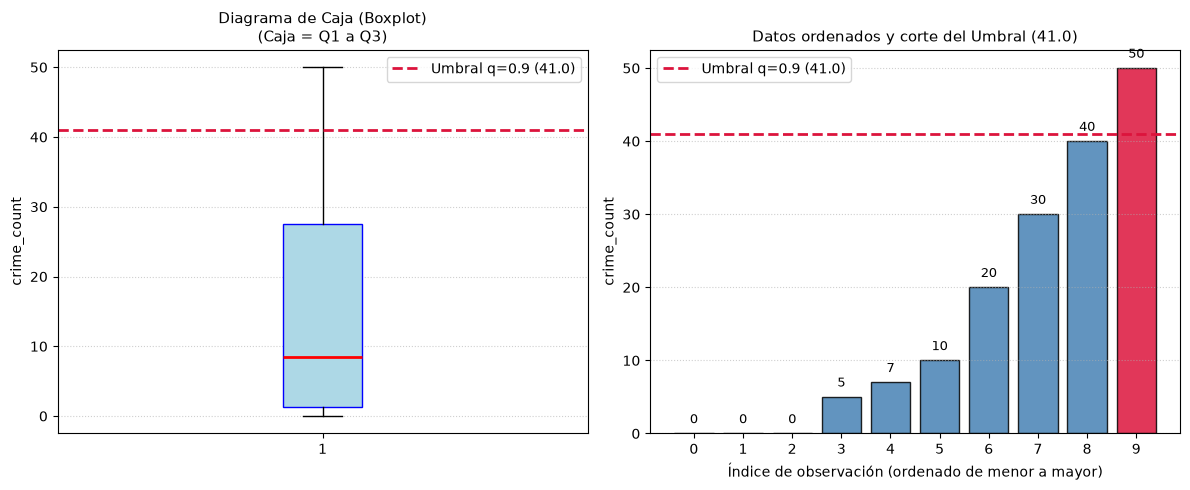

In [35]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Tus datos de entrada
data = [10, 20, 30, 40, 50, 5, 7, 0, 0, 0]
df = pd.DataFrame({"crime_count": data})

# 2. Cálculo del umbral (percentil 90)
q = 0.9
threshold = float(df["crime_count"].quantile(q))  # Resultado: 41.0

# 3. Configuración del lienzo con 2 gráficos
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# --- GRÁFICO 1: Boxplot (El "rectángulo" de cuantiles) ---
ax1.boxplot(
    df["crime_count"],
    vert=True,
    patch_artist=True,
    boxprops=dict(facecolor="lightblue", color="blue"),
    medianprops=dict(color="red", linewidth=2),
)
# Línea roja para el cuantil 0.9 (41.0)
ax1.axhline(
    threshold,
    color="crimson",
    linestyle="--",
    linewidth=2,
    label=f"Umbral q={q} ({threshold})",
)
ax1.set_title("Diagrama de Caja (Boxplot)\n(Caja = Q1 a Q3)", fontsize=11)
ax1.set_ylabel("crime_count")
ax1.legend()
ax1.grid(axis="y", linestyle=":", alpha=0.6)

# --- GRÁFICO 2: Barras ordenadas con la línea de corte ---
sorted_counts = df["crime_count"].sort_values().reset_index(drop=True)
colors = ["crimson" if x > threshold else "steelblue" for x in sorted_counts]

bars = ax2.bar(
    range(len(sorted_counts)),
    sorted_counts,
    color=colors,
    edgecolor="black",
    alpha=0.85,
)
ax2.axhline(
    threshold,
    color="crimson",
    linestyle="--",
    linewidth=2,
    label=f"Umbral q={q} ({threshold})",
)
ax2.set_title("Datos ordenados y corte del Umbral (41.0)", fontsize=11)
ax2.set_xlabel("Índice de observación (ordenado de menor a mayor)")
ax2.set_ylabel("crime_count")
ax2.set_xticks(range(len(sorted_counts)))
ax2.legend()
ax2.grid(axis="y", linestyle=":", alpha=0.6)

# Etiquetas numéricas sobre cada barra
for bar in bars:
  yval = bar.get_height()
  ax2.text(
      bar.get_x() + bar.get_width() / 2.0,
      yval + 1,
      int(yval),
      ha="center",
      va="bottom",
      fontsize=9,
  )

plt.tight_layout()
plt.show()

"Al analizar la distribución mediante el cálculo de cuantiles, observamos que el 90% de las zonas registra 41 delitos o menos, mientras que solo el 10% restante más crítico supera este umbral, alcanzando el valor máximo observado de 50 delitos."   